# SP-LIME run explanations

Select three representative run-start explanations from all stored sample runs.

Move to the repository root before importing project modules.

In [1]:
from pathlib import Path

%cd ../..

d:\User Installed Folders\Master Thesis


Load the agent and initialize a controller.

In [2]:
from stable_baselines3 import SAC

from Explanations.Lime.lime import LimeExplainer
from Explanations.Lime.lime_model import RunValueClass
from Explanations.Lime.peragentcontroller import PerAgentController
from Explanations.Lime.sp_lime import (
    load_run_candidates,
    select_run_explanations,
)
from Simulation.Auxilaries.sim_config import sim_config

model_path = Path("sac_ship_07_0_1.6m.zip")
model = SAC.load(model_path)

pac = PerAgentController(sim_config, model)
pac.new_training_instance()
lime = LimeExplainer(pac)

Load one candidate for each stored run. The candidate state is reconstructed from its scenario start, so the step logs are not required.

In [3]:
samples_path = Path("Explanations/Samples")
candidates = load_run_candidates(samples_path, sim_config)
print(f"Loaded {len(candidates)} run candidates.")

Loaded 73 run candidates.


Select three explanations for run stepcount. Each run is explained with 100 local LIME perturbations.

In [4]:
selected = select_run_explanations(
    lime,
    candidates,
    RunValueClass.REWARD_DELTA,
    k=3,
    num_samples=100,
    explanation_num_features=8,
    selection_num_features=5,
    discretize_continuous=False,
)

print([result.id for result in selected])

['run0072', 'run0071', 'run0070']


Inspect the selected explanations and their associated scenario contexts.

run0072: start state = [ 0.187213   -0.892       0.24865927  0.96859102  0.          0.
  0.64520624  0.892     ]


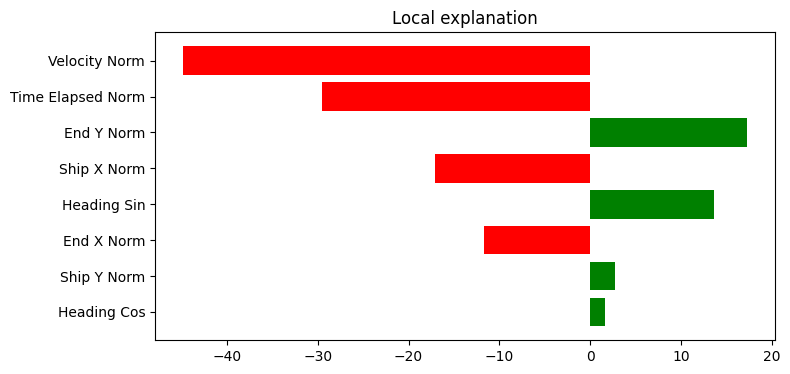

run0071: start state = [ 0.27142105 -0.892       0.04143057  0.99914139  0.          0.
  0.34539669  0.892     ]


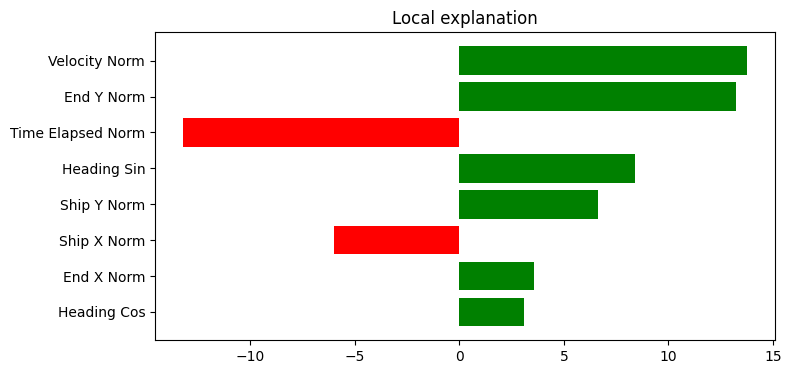

run0070: start state = [ 0.59772735 -0.892      -0.80070928  0.59905312  0.          0.
 -0.892       0.22254411]


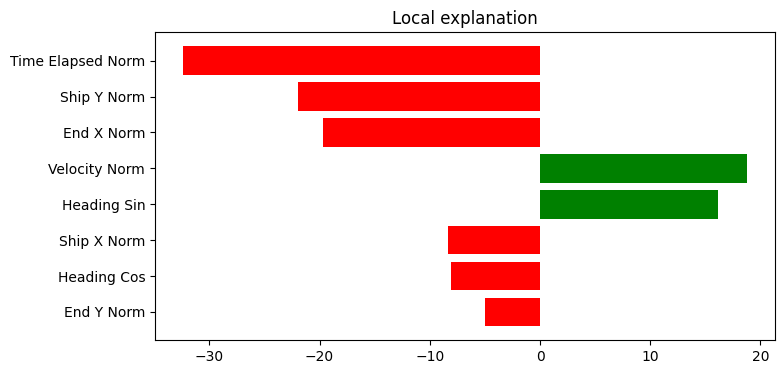

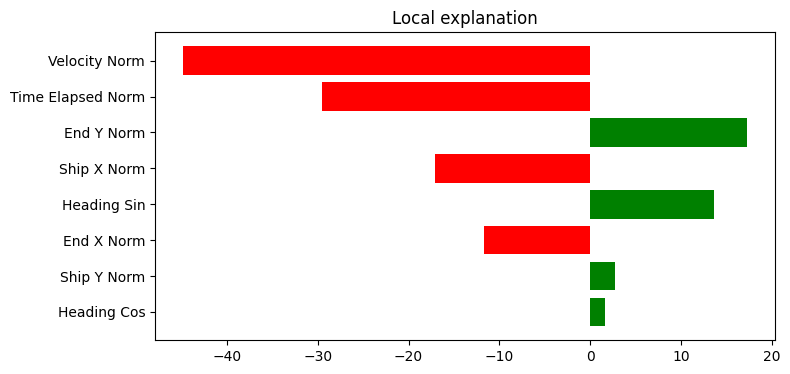

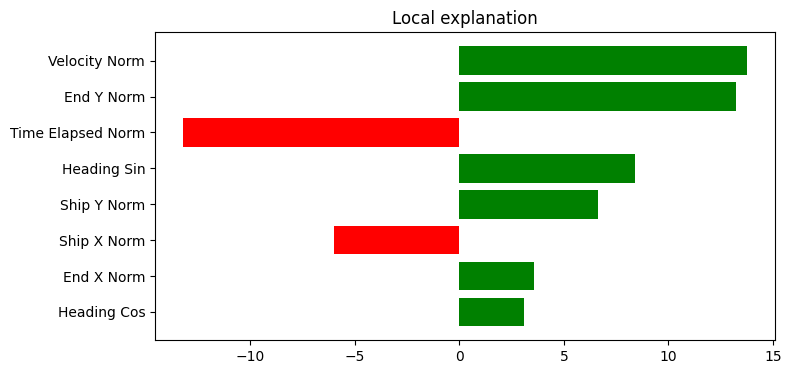

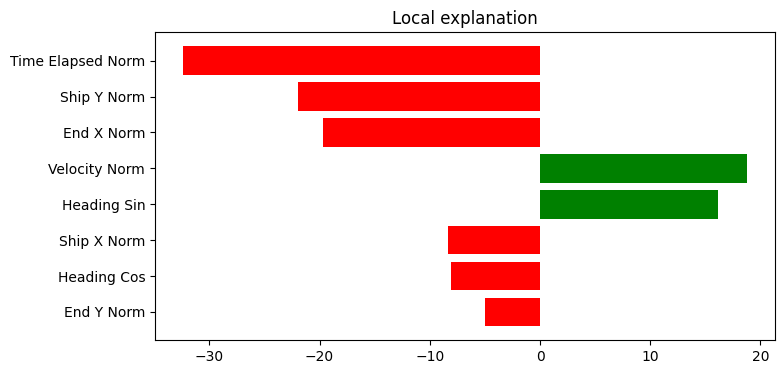

In [5]:
import matplotlib.pyplot as plt
from IPython.display import display

for result in selected:
    print(f"{result.id}: start state = {result.state}")
    figure = result.explanation.as_pyplot_figure(figsize=(8, 4))
    display(figure)
    plt.close(figure)